# Preference-aware Pareto decisions and experimental FPBI

* Contributors: [M-Colley](https://github.com/M-Colley)
* Last updated: October 21, 2026
* Executed with BoTorch 0.18.1 and PyTorch 2.14.1+cpu; the setup cell reports the versions used on a rerun.

A multiobjective optimizer returns alternatives. A separate decision is needed when we must recommend one tested design. This notebook implements that final, **a posteriori** step using the published two-stage rule of [Schmitt, Hoffmann, Rodemann, and Adamy (2022)](https://doi.org/10.3390/inventions7030046): identify a knee region, then select within it using a preference hyperplane.

We compare this rule with an ordinary normalized weighted cost and the closest-to-ideal recommendation. The example also shows an important tradeoff: a knee restriction can exclude an extreme design that is entirely legitimate under the supplied preferences. The method expresses an additional preference for compromise; it does not discover the decision maker's true utility.

The second part generates a small front using experimental focus point boundary intersection (FPBI), including constraints, solver diagnostics, and a BoTorch model adapter. The final section separates working functionality from the measured utility, coverage, runtime, and memory tradeoffs.


In [1]:
import matplotlib.pyplot as plt
import torch

import botorch
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch_community.utils.multi_objective.decision_making import (
    knee_region,
    select_preferred,
)

torch.set_default_dtype(torch.float64)
print(f"BoTorch {botorch.__version__}; PyTorch {torch.__version__}")


C:\Users\Mark\Desktop\openbo\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


BoTorch 0.18.1; PyTorch 2.14.1+cpu


## Recommend from measured outcomes

Suppose the rows below are exact outcomes of nine tested designs, with two costs to minimize. The last design is dominated. We store rewards `train_Y = -observed_costs`, so the recommendation functions use BoTorch's usual maximization convention. With noisy measurements, deciding what counts as a credible Pareto alternative requires additional uncertainty analysis.

The selector filters dominated rows and keeps the first duplicate before computing objective ranges. Returned indices always refer to the original rows, making it straightforward to retrieve a design from `train_X`.


In [2]:
train_X = torch.linspace(0, 1, 9).unsqueeze(-1)
observed_costs = torch.tensor(
    [
        [0.00, 1.00],
        [0.04, 0.78],
        [0.10, 0.60],
        [0.20, 0.40],
        [0.35, 0.27],
        [0.55, 0.18],
        [0.75, 0.09],
        [1.00, 0.00],
        [0.60, 0.65],  # Dominated by multiple tested designs.
    ]
)
train_Y = -observed_costs
pareto = is_non_dominated(train_Y)
preferences = torch.tensor([0.95, 0.05])
alpha = 0.8

in_knee = knee_region(train_Y, alpha=alpha)
recommended_index = select_preferred(train_Y, preferences, alpha=alpha)
recommended_X = train_X[recommended_index]

assert not pareto[-1]
assert recommended_index.item() == 3
print("Original row:", recommended_index.item())
print("Recommended design:", recommended_X.tolist())
print("Observed costs:", observed_costs[recommended_index].tolist())


Original row: 3
Recommended design: [0.375]
Observed costs: [0.2, 0.4]


## The published geometry

Let $z^i$ be normalized **minimization costs**, with the componentwise best and worst Pareto outcomes mapped to zero and one. This orientation also applies when the input contains maximization rewards. The source calls the componentwise best vector the Utopia point; no strict improvement offset is introduced here.

Equations (9)–(11) of Schmitt et al. choose

$$q=\operatorname*{arg\,max}_i\|z^i\|_2,\qquad
\delta_i=\frac{\mathbf{1}^{\mathsf T}(z^q-z^i)}{\sqrt m},\qquad
K_\alpha=\lbrace i:\delta_i\geq\alpha\max_j\delta_j\rbrace,\quad \alpha\in[0,1].$$

The preference-plane condition in Equation (13) is equivalent to

$$b=\operatorname*{arg\,min}_{i\in K_\alpha}p^{\mathsf T}z^i.$$

Larger nonnegative preference coefficients prioritize reducing their corresponding normalized costs. Scaling every coefficient by the same positive constant has no effect. `alpha` controls the allowed knee region, not a confidence level or a probability of human error. The discrete choice is not differentiable. Exact score ties select the earliest retained input row.


In [3]:
# Normalize all three comparison methods using the same Pareto ranges.
front_costs = observed_costs[pareto]
ideal = front_costs.amin(dim=0)
nadir = front_costs.amax(dim=0)
normalized_costs = (observed_costs - ideal) / (nadir - ideal)

weighted_scores = (normalized_costs * preferences).sum(dim=-1)
ideal_distances = torch.linalg.vector_norm(normalized_costs, dim=-1)
weighted_index = weighted_scores.masked_fill(~pareto, torch.inf).argmin()
ideal_index = ideal_distances.masked_fill(~pareto, torch.inf).argmin()

methods = {
    "Normalized weighted cost": weighted_index,
    "Closest to ideal": ideal_index,
    "Knee + preference plane": recommended_index,
}
for name, index in methods.items():
    print(
        f"{name:26s} row={index.item()}  "
        f"costs={observed_costs[index].tolist()}  "
        f"weighted cost={weighted_scores[index].item():.4f}"
    )

assert weighted_index.item() == 0
assert ideal_index.item() == 4
assert not in_knee[weighted_index]  # A legitimate preference-optimal extreme.
assert in_knee[recommended_index]


Normalized weighted cost   row=0  costs=[0.0, 1.0]  weighted cost=0.0500
Closest to ideal           row=4  costs=[0.35, 0.27]  weighted cost=0.3460
Knee + preference plane    row=3  costs=[0.2, 0.4]  weighted cost=0.2100


The ordinary weighted rule chooses row 0, which best reflects the stated linear utility over these normalized outcomes. The knee rule excludes it and chooses row 3. Closest-to-ideal ignores the supplied preference vector and chooses row 4. These are different decision policies, rather than an ordering from worse to better.

The left panel shows the distance plane and the threshold that defines the knee region. The right panel changes the first preference coefficient while holding the same tested outcomes fixed. A finite set produces stepwise recommendations. The knee restriction limits how far they can move toward either extreme.


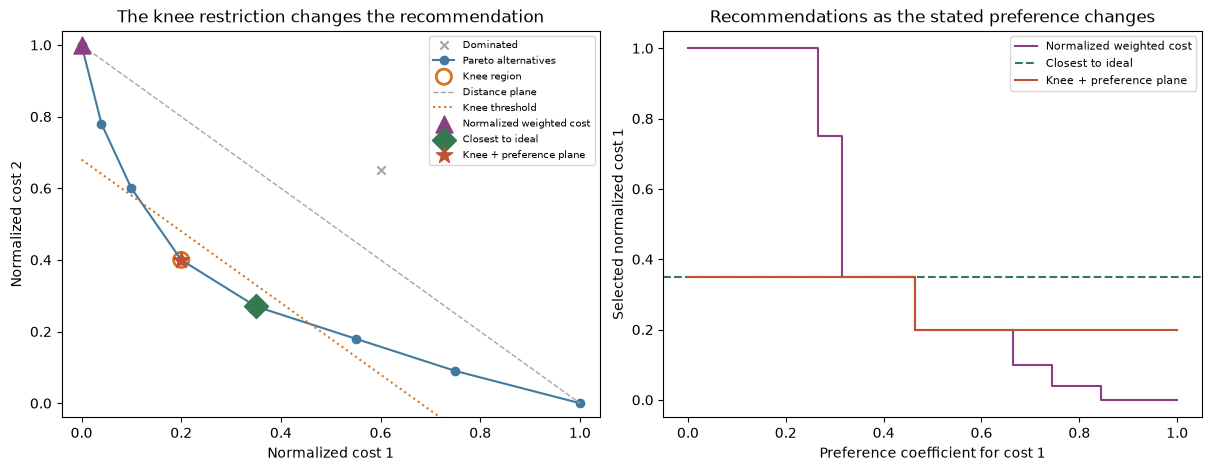

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
ax = axes[0]
z = normalized_costs.detach().cpu()
ax.scatter(z[~pareto, 0], z[~pareto, 1], color="0.65", marker="x", label="Dominated")
ax.plot(z[pareto, 0], z[pareto, 1], "o-", color="#427A9F", label="Pareto alternatives")
ax.scatter(z[in_knee, 0], z[in_knee, 1], s=120, facecolors="none",
           edgecolors="#D47724", linewidths=2, label="Knee region")

front_z = normalized_costs[pareto]
q = torch.linalg.vector_norm(front_z, dim=-1).argmax()
plane_sum = front_z[q].sum().item()
delta_max = plane_sum - front_z.sum(dim=-1).min().item()
xx = torch.linspace(0, 1, 101)
ax.plot(xx, plane_sum - xx, "--", color="0.65", linewidth=1,
        label="Distance plane")
ax.plot(xx, plane_sum - alpha * delta_max - xx, ":", color="#D47724",
        linewidth=1.5, label="Knee threshold")

markers = ["^", "D", "*"]
colors = ["#8A3F82", "#367850", "#C54F35"]
for (name, index), marker, color in zip(methods.items(), markers, colors):
    ax.scatter(z[index, 0], z[index, 1], s=150, marker=marker,
               color=color, zorder=5, label=name)
ax.set(xlim=(-0.04, 1.04), ylim=(-0.04, 1.04),
       xlabel="Normalized cost 1", ylabel="Normalized cost 2",
       title="The knee restriction changes the recommendation")
ax.legend(fontsize=7.5, loc="upper right")

first_preferences = torch.linspace(0, 1, 101)
preference_grid = torch.stack([first_preferences, 1 - first_preferences], dim=-1)
catalogs = train_Y.expand(len(preference_grid), -1, -1)
knee_indices = select_preferred(catalogs, preference_grid, alpha=alpha)
full_scores = (normalized_costs.unsqueeze(0) * preference_grid.unsqueeze(1)).sum(-1)
full_indices = full_scores.masked_fill(~pareto.unsqueeze(0), torch.inf).argmin(-1)

ax = axes[1]
ax.step(first_preferences, normalized_costs[full_indices, 0], where="mid",
        color=colors[0], label="Normalized weighted cost")
ax.axhline(normalized_costs[ideal_index, 0], color=colors[1], linestyle="--",
           label="Closest to ideal")
ax.step(first_preferences, normalized_costs[knee_indices, 0], where="mid",
        color=colors[2], label="Knee + preference plane")
ax.set(xlabel="Preference coefficient for cost 1", ylabel="Selected normalized cost 1",
       title="Recommendations as the stated preference changes")
ax.legend(fontsize=8)
plt.show()


## Signed distances: `alpha=0` has a subtle boundary

Equation (10) uses a **signed** distance, not its absolute value. The largest Euclidean norm need not identify the largest sum of normalized costs. A Pareto alternative can therefore lie on the negative side of the distance plane and have $\delta_i<0$.

The three-objective example below is already normalized and every row is nondominated. Row 1 has sum 2.4 but norm below $\sqrt{2}$. The source distance plane passes through the first maximum-norm row, whose sum is 2. Consequently `alpha=0` still excludes row 1. Replacing the norm-based anchor with a largest-sum anchor, or taking absolute distances, would implement a different method.


In [5]:
nonconvex_costs = torch.tensor(
    [[1.0, 1.0, 0.0], [0.8, 0.8, 0.8], [0.0, 1.0, 1.0], [1.0, 0.0, 1.0]]
)
assert is_non_dominated(-nonconvex_costs).all()
q3 = torch.linalg.vector_norm(nonconvex_costs, dim=-1).argmax()
signed_distances = (
    nonconvex_costs[q3].sum() - nonconvex_costs.sum(dim=-1)
) / (3 ** 0.5)
mask_at_zero = knee_region(nonconvex_costs, alpha=0, maximize=False)
print("Signed distances:", signed_distances.tolist())
print("Knee mask at alpha=0:", mask_at_zero.tolist())
assert mask_at_zero.tolist() == [True, False, True, True]


Signed distances: [0.0, -0.23094010767585052, 0.0, 0.0]
Knee mask at alpha=0: [True, False, True, True]


## Batched recommendations

Outcome tensors have shape `(..., n, m)` and preference tensors have shape `(..., m)`. Preferences broadcast over the outcome batch dimensions. Here the same catalog is evaluated under three preference vectors; this also covers independently supplied catalogs of the same shape.


In [6]:
preference_batch = torch.tensor([[0.95, 0.05], [0.50, 0.50], [0.05, 0.95]])
outcome_batch = train_Y.expand(3, -1, -1)
batch_indices = select_preferred(outcome_batch, preference_batch, alpha=alpha)
batch_masks = knee_region(outcome_batch, alpha=alpha)
assert batch_indices.shape == torch.Size([3])
assert batch_masks.shape == torch.Size([3, len(train_Y)])
print("Original rows:", batch_indices.tolist())
print("Recommended costs:", observed_costs[batch_indices].tolist())


Original rows: [3, 3, 4]
Recommended costs: [[0.2, 0.4], [0.2, 0.4], [0.35, 0.27]]


## Workflow: front generation, decision, and validation

The selector above recommends among **measured alternatives**. An outcome index retrieves the corresponding tested design. Preferences can change while those outcomes remain fixed; no surrogate retraining is needed to rerank that catalog.

Front generation is a separate task. FPBI (Schmitt et al., Section 4, Equations (16)–(27)) uses individual objective minima, a focus point in normalized cost coordinates, and a grid of constrained scalar optimization problems. This community module includes an experimental continuous FPBI solver using local multistart SLSQP, alongside `fpbi_geometry` and `sample_model_fpbi`.

For a fitted model, these routines approximate a front of **posterior mean predictions**. That does not establish measured performance, posterior Pareto probabilities, or a good next information-gathering experiment. A practical workflow is: generate alternatives, inspect diagnostics and feasibility, apply an explicit decision policy, and validate the recommended design in the application.


In [7]:
from botorch.models.deterministic import GenericDeterministicModel
from botorch_community.utils.multi_objective.fpbi import (
    fpbi_geometry,
    sample_fpbi,
    sample_model_fpbi,
)


def quadratic_costs(X):
    x = X[..., :1]
    return torch.cat((x.square(), (1 - x).square()), dim=-1)


def interval_constraints(X):
    # The public callback convention is g(X) >= 0.
    x = X[..., :1]
    return torch.cat((x - 0.2, 0.8 - x), dim=-1)


bounds = torch.tensor([[0.0], [1.0]])
fpbi_options = {
    "n_steps": 3,
    "maximize": False,  # This objective callback returns minimization costs.
    "num_restarts": 2,
    "seed": 0,
    "maxiter": 100,
    "inequality_constraints": interval_constraints,
}
result = sample_fpbi(quadratic_costs, bounds, **fpbi_options)

assert result.X.ndim == 2 and result.Y.shape == (len(result.X), 2)
assert torch.allclose(result.Y, quadratic_costs(result.X))
assert interval_constraints(result.X).min() >= -1e-6
print("FPBI decision vectors:", result.X.squeeze(-1).tolist())
print("Returned cost outcomes:", result.Y.tolist())


FPBI decision vectors: [0.19999999999999996, 0.8000000000000003, 0.3999999999999978, 0.5999999999999958]
Returned cost outcomes: [[0.03999999999999998, 0.6400000000000001], [0.6400000000000005, 0.0399999999999999], [0.15999999999999825, 0.36000000000000265], [0.35999999999999494, 0.1600000000000034]]


This small example has a known front and cheap analytic evaluations. It is a functionality demonstration, not an additional benchmark. Bounds and the interval constraints apply both when finding the individual extrema and when solving the FPBI subproblems. Equalities can be supplied through `equality_constraints`, with zero denoting feasibility.

The solver keeps only converged, independently feasibility-checked results. An unsolved individual extreme raises an error; failed ray attempts remain visible in `diagnostics` and `ray_succeeded`. The final pool includes individual extrema and filters dominance and near duplicates among its sampled outcomes. Local optimization and sampled nondomination do not certify a globally complete Pareto front.


In [8]:
accepted_attempts = [d for d in result.diagnostics if d.accepted]
rejected_attempts = [d for d in result.diagnostics if not d.accepted]
max_accepted_violation = max(d.max_violation for d in accepted_attempts)
print("Accepted solver attempts:", len(accepted_attempts))
print("Rejected solver attempts:", len(rejected_attempts))
print("Ray success mask:", result.ray_succeeded.tolist())
print("Largest accepted constraint violation:", max_accepted_violation)
assert max_accepted_violation <= 1e-6

# Original indices now refer to the FPBI result catalog, not train_X above.
fpbi_preference = torch.tensor([0.7, 0.3])
fpbi_choice = select_preferred(-result.Y, fpbi_preference, alpha=0.5)
print("Recommended generated design:", result.X[fpbi_choice].tolist())


Accepted solver attempts: 16
Rejected solver attempts: 0
Ray success mask: [True, True, True]
Largest accepted constraint violation: 5.721170065475789e-13
Recommended generated design: [0.3999999999999978]


### Inspect the FPBI geometry

`fpbi_geometry` can inspect known individual extreme outcomes without running another optimizer. `focus` is a point in **normalized minimization-cost coordinates**, even if the supplied objectives are maximized. Its default is the componentwise ideal point (zero); it is independent of the selector's preference vector. The paper does not prescribe a preference-to-focus mapping.

The source grid is intentionally asymmetric: its sample positions omit the negative endpoint and include the positive endpoint. `n_steps` points along each of `m-1` directions produce `n_steps**(m-1)` nominal rays. Degenerate directions can lead to repeated anchors. Flat observed extreme ranges are projected out, and rank-deficient constructions use a reported deterministic fallback; these are numerical extensions needed when the source formula is undefined.


In [9]:
geometry = fpbi_geometry(result.extreme_Y, n_steps=3, maximize=False)
print("Normalized cost-space focus:", geometry.focus.tolist())
print("Search direction:", geometry.direction.tolist())
print("Active observed objective ranges:", geometry.active_objectives.tolist())
print("Normalized anchors:", geometry.anchors.tolist())
print("Degenerate:", bool(geometry.degenerate))
print("Fallback basis used:", bool(geometry.used_fallback_basis))

assert geometry.anchors.shape == (3, 2)
assert torch.equal(geometry.focus, torch.zeros(2))


Normalized cost-space focus: [0.0, 0.0]
Search direction: [-0.5, -0.5]
Active observed objective ranges: [True, True]
Normalized anchors: [[0.33333333333333337, 0.6666666666666666], [0.6666666666666666, 0.33333333333333337], [1.0, 0.0]]
Degenerate: False
Fallback basis used: False


### The BoTorch posterior-mean adapter

The same front-generation API works through `model.posterior(X).mean`. Here a real `GenericDeterministicModel` returns the exact analytic costs so the two interfaces can be checked directly. With a fitted GP, this routine instead optimizes its predictions; it does not fit the model or evaluate the physical experiment. The adapter evaluates callbacks on the input device, while SciPy's local optimization runs on the CPU using finite differences.


Model-adapter cost outcomes: [[0.03999999999999998, 0.6400000000000001], [0.6400000000000005, 0.0399999999999999], [0.15999999999999825, 0.36000000000000265], [0.35999999999999494, 0.1600000000000034]]


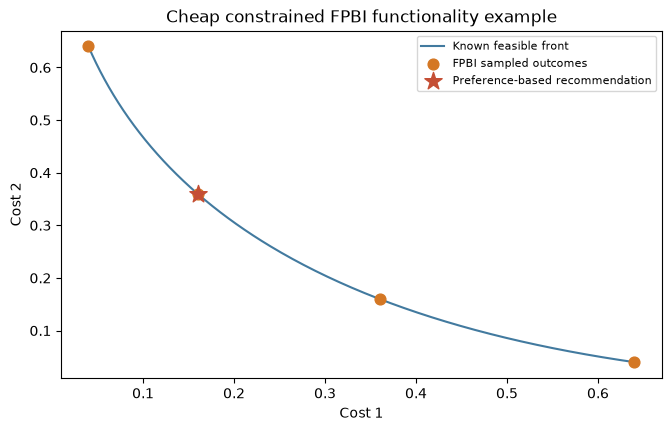

In [10]:
model = GenericDeterministicModel(f=quadratic_costs, num_outputs=2)
model_result = sample_model_fpbi(model, bounds, **fpbi_options)
assert torch.allclose(model_result.Y, quadratic_costs(model_result.X))
assert interval_constraints(model_result.X).min() >= -1e-6
print("Model-adapter cost outcomes:", model_result.Y.tolist())

# Plotting this known analytic curve is separate from front generation.
curve_X = torch.linspace(0.2, 0.8, 301).unsqueeze(-1)
curve_Y = quadratic_costs(curve_X)
fig, ax = plt.subplots(figsize=(6.6, 4.2), constrained_layout=True)
ax.plot(curve_Y[:, 0], curve_Y[:, 1], color="#427A9F", label="Known feasible front")
ax.scatter(result.Y[:, 0], result.Y[:, 1], color="#D47724", s=60,
           label="FPBI sampled outcomes", zorder=3)
ax.scatter(result.Y[fpbi_choice, 0], result.Y[fpbi_choice, 1], marker="*",
           color="#C54F35", s=170, label="Preference-based recommendation", zorder=4)
ax.set(xlabel="Cost 1", ylabel="Cost 2",
       title="Cheap constrained FPBI functionality example")
ax.legend(fontsize=8)
plt.show()


## Evidence: working APIs and measured outcomes are separate findings

The examples above demonstrate the APIs, original-row indexing, constraints, and solver diagnostics. They do not show that the knee prior improves a decision maker's utility, that FPBI produces better fronts, or that tensor vectorization always runs faster.

The companion [README and evidence guide](https://github.com/meta-pytorch/botorch/blob/main/notebooks_community/pareto_decision_making/README.md) records reproducible protocols, source hashes, raw summaries, and limitations. The version under review is available in [draft PR #3531](https://github.com/meta-pytorch/botorch/pull/3531). Canonical repository links below refer to the proposed paths on `main` after merging.

### Fixed-archive selection replay: the knee prior hurt the declared utilities

In 100 fixed MOBO archives from four analytic problems and five seeds, each with 50 evaluated designs, selectors chose from exactly the same candidates. The knee threshold was `alpha=0.5`. The replay used recorded Gaussian objective errors and separately simulated multiplicative preference-weight errors. It performed no new optimization, model fitting, or experimental evaluations.

For the headline condition (recorded objective errors, exact preference coefficients, noisy-optimization archives pooled), the knee-weighted rule increased the final selected design's within-archive normalized regret:

| Declared utility | Matching ordinary rule's regret | Knee-weighted regret | Knee rule's extra clean-feedback regret |
| --- | ---: | ---: | ---: |
| Linear | 0.237706 | 0.332108 | 0.072301 |
| Quadratic distance | 0.452719 | 0.547495 | 0.032571 |

The linear reference was ordinary weighted cost; the quadratic reference was weighted distance to the ideal. Clean-feedback prices use exact outcomes and true preference coefficients on the **same archive**, rather than a different optimization run. The knee selector still uses linear preference weights under quadratic evaluation, so that contrast includes decision-rule mismatch. Evaluator normalization is fixed from the archive's true Pareto ranges and is oracle-only scoring information.

These are descriptive simulation results with only four correlated problem clusters. They support neither a generic robustness claim nor a human-benefit claim. See the [selection summary](https://github.com/meta-pytorch/botorch/blob/main/notebooks_community/pareto_decision_making/evidence/selection/comparison_summary.csv).

### FPBI front generation: the small comparison favored NSGA-II

A separate 36-run CPU experiment compared four low-dimensional analytic cases, three seeds, FPBI, and two arms using upstream BoTorch's NSGA-II wrapper. One arm shared an output cap; the other approximately matched FPBI's counted objective-point evaluations by rounding to complete NSGA-II generations.

All runs completed, but median hypervolume, reference-to-approximation IGD, and generation time favored NSGA-II in every case under both comparator policies. The common cap did not produce equal retained cardinality: typical FPBI/NSGA-II counts were 6/7 in two objectives and 11/12 on the sphere example. Finite differences and repeated diagnostic evaluations were counted as model objective-point evaluations, rather than expensive physical experiments. The comparison used deterministic model means and provides no general claim about noisy BO or real GP workloads.

See the [FPBI summary](https://github.com/meta-pytorch/botorch/blob/main/notebooks_community/pareto_decision_making/evidence/fpbi/summary.csv) for actual counts, failures, quality metrics, and timing. Those FPBI timings measured the original OpenBO implementation; the upstream FPBI port was checked separately for functionality and was not rebenchmarked. FPBI remains experimental; these results give no reason to prefer it by default over upstream NSGA-II.

### Selector runtime: improvements, regressions, and a memory tradeoff

Before/after measurements compared the complete original OpenBO selector with the vectorized upstream candidate, retaining exact parity for 396 selected indices and 79,104 knee-mask entries. The included candidate snapshot has the same source hash as the proposed `decision_making.py` module. The candidate was faster in 11/12 CPU configurations and 4/12 CUDA configurations. Performance depended strongly on shape, dtype, and the installed Pareto implementation.

In the worst measured CUDA case, float32 input with shape `(1, 1024, 3)`, median selection time rose from 6.862 ms to 165.3 ms, about **24.1 times slower**. In that same configuration, the peak live CUDA allocator increment fell from 6,314,496 to 53,760 bytes. This is a runtime–memory tradeoff, not a universal speed improvement. Peak live allocator increment excludes reserved cache and total process/device usage.

These measurements used one laptop, two warmups and five timed calls per configuration, with GPU synchronization. They concern the included before/after source snapshots, rather than a cross-version or cross-hardware guarantee. Other machine activity was not fully controlled. See the [selector timings](https://github.com/meta-pytorch/botorch/blob/main/notebooks_community/pareto_decision_making/evidence/selector/timings.csv) and the evidence guide for the exact source versions and observed ranges.

## When to use these components

Use the selector when a knee preference is a deliberate part of the decision policy and an explicit compromise is acceptable. Ordinary weighted cost is the direct choice for a stated linear utility over normalized outcomes. A knee restriction can discard its legitimate optimum, as the first example and replay demonstrate.

Use experimental FPBI to inspect or reproduce its geometry on small continuous problems with cheap objective/model evaluations and explicit constraints. Inspect every solver diagnostic and compare front quality and effort with an alternative generator for the actual problem. The nominal ray count grows exponentially with the number of objectives.

Normalization deserves particular care in both components. Sample-derived ranges change as an archive evolves; new extreme observations can alter both the knee region and the interpretation of the same preference vector. A flat range across individual extrema does not prove global constancy over unobserved designs. Neither component learns human preferences, models human feedback mistakes, certifies globally complete fronts, or establishes MPC stability.

## Reference

Thomas Schmitt, Matthias Hoffmann, Tobias Rodemann, and Jürgen Adamy. 2022. [Incorporating Human Preferences in Decision Making for Dynamic Multi-Objective Optimization in Model Predictive Control](https://doi.org/10.3390/inventions7030046). *Inventions* 7(3), 46. The selector follows Equations (8)–(13); FPBI follows Equations (16)–(27), with documented numerical safeguards and local-solver diagnostics.
